# Sistemas Inteligentes

## Exercício Computacional 4 - Agrupamento (Clusterização)

### Identificação do Aluno

#### Nome Completo

Nicolas Garcia de Souza Santos

#### RA

11202520227

## Instruções

1. Escolha um dataset, identifique-o e mostre suas características, então indique quais são os seus objetivos com esse dataset (no campo correspondente).

2. Com o dataset já importado para o notebook, faça os pré-processamentos que julgar necessários e, se for conveniente, efetue uma redução de dimensionalidade utilizando um método compatível com seus dados.

3. Utilize ao menos um método de Cross-Validation de sua preferência.

4. Escolha dois métodos de agrupamento (clusterização) para realizar abordagens distintas, então aplique-os ao dataset para chegar ao objetivo indicado por você no próprio notebook.

5. Utilize células intermediárias de tipo _Markdown_ para explicar o que é feito em cada célula de código. Mas não deixe de utilizar comentários breves e pertinentes dentro do próprio código. Isto significa que o desenvolvimento NÃO deve ser feito em uma única célula.

6. Sempre que for cabível, exiba as figuras, os gráficos, os valores (ao menos parte deles) etc., mas procure sempre manter um capricho em todas as saídas.

7. Ao final, comente da forma mais completa possível os resultados obtidos, sempre sugerindo o que poderia ser feito para melhorá-los e fornecendo elementos que contribuam para a sua compreensão.

8. Respeitem as regras gramaticais e procurem manter coesão, coerência e fluidez em seus textos.

9. Apesar de a análise dos resultados ser mais importante do que o código em si, serão analisados critérios como organização e clareza do código, então evitem códigos "poluídos" e confusos.

### Dataset

#### Nome do Dataset

Wine Recognition Dataset

#### Características do Dataset

O dataset contém 178 amostras de vinhos cultivados na mesma região da Itália, mas derivados de três cultivares diferentes. Possui 13 atributos numéricos contínuos, representando análises químicas como teor alcoólico, ácido málico, magnésio, intensidade de cor, entre outros. Não há dados faltantes.

#### Fonte do Dataset

 UCI Machine Learning Repository (disponibilizado nativamente através do módulo

### Objetivos

O objetivo principal é identificar agrupamentos naturais que correspondam às três cultivares de vinho, utilizando aprendizado não supervisionado. Para isso, será feita a padronização dos dados e a redução de dimensionalidade com PCA. Serão aplicados e comparados os algoritmos K-Means (baseado em centroides) e Agglomerative Clustering (hierárquico). A estabilidade dos agrupamentos será avaliada por meio de validação cruzada adaptada para clusterização, utilizando o Silhouette Score.

## Desenvolvimento

### Importação de Bibliotecas e Carregamento dos Dados
Nesta etapa, importamos as ferramentas necessárias e carregamos o dataset Wine. Os dados são convertidos para um DataFrame Pandas para facilitar a manipulação.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from sklearn.model_selection import KFold

# Configuração de estilo dos gráficos
sns.set_theme(style="whitegrid")

# Carregamento do dataset
wine = load_wine()
X = pd.DataFrame(wine.data, columns=wine.feature_names)

print(f"Dimensões do dataset: {X.shape}")
display(X.head())

Dimensões do dataset: (178, 13)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


### Pré-processamento e Redução de Dimensionalidade
Como as variáveis possuem escalas muito diferentes (ex: Prolina na casa dos milhares e Álcool na casa das dezenas), é imprescindível padronizar os dados (média 0, variância 1). Em seguida, aplicamos o PCA (Análise de Componentes Principais) para reduzir as 13 dimensões originais para apenas 2, facilitando a visualização e mitigando a "maldição da dimensionalidade".

Variância explicada pelos 2 componentes: 55.41%


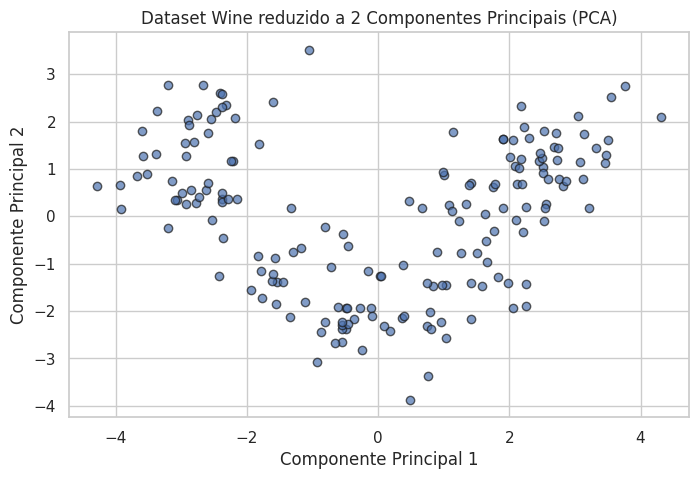

In [2]:
# Padronização dos dados (Z-score)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Aplicação do PCA para 2 componentes principais
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled)

print(f"Variância explicada pelos 2 componentes: {sum(pca.explained_variance_ratio_):.2%}")

# Visualização da distribuição nos componentes principais
plt.figure(figsize=(8, 5))
plt.scatter(X_pca[:, 0], X_pca[:, 1], alpha=0.7, edgecolors='k')
plt.title("Dataset Wine reduzido a 2 Componentes Principais (PCA)")
plt.xlabel("Componente Principal 1")
plt.ylabel("Componente Principal 2")
plt.show()

### Método 1: K-Means
O K-Means agrupa os dados baseando-se na distância até os centroides. Sabendo que existem 3 cultivares originais, vamos configurar n_clusters=3. Avaliaremos a qualidade do agrupamento usando o Silhouette Score (quanto mais próximo de 1, melhor o agrupamento).

Silhouette Score (K-Means): 0.5611


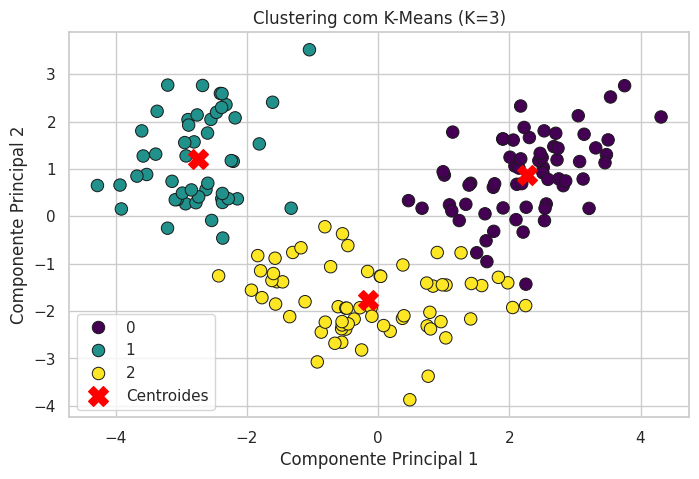

In [3]:
# Instanciando e treinando o K-Means
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
kmeans_labels = kmeans.fit_predict(X_pca)

# Avaliação K-Means
sil_kmeans = silhouette_score(X_pca, kmeans_labels)
print(f"Silhouette Score (K-Means): {sil_kmeans:.4f}")

# Plotagem dos resultados
plt.figure(figsize=(8, 5))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=kmeans_labels, palette='viridis', s=80, edgecolor='k')
# Plotando os centroides
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],
            s=200, c='red', marker='X', label='Centroides')
plt.title("Clustering com K-Means (K=3)")
plt.xlabel("Componente Principal 1")
plt.ylabel("Componente Principal 2")
plt.legend()
plt.show()

### Método 2: Agglomerative Clustering (Agrupamento Hierárquico)
Diferente do K-Means, o Agglomerative Clustering começa com cada ponto como um cluster independente e os funde iterativamente (abordagem *bottom-up*). Utilizaremos a ligação de Ward, que minimiza a variância dentro dos clusters.

Silhouette Score (Agglomerative): 0.5591


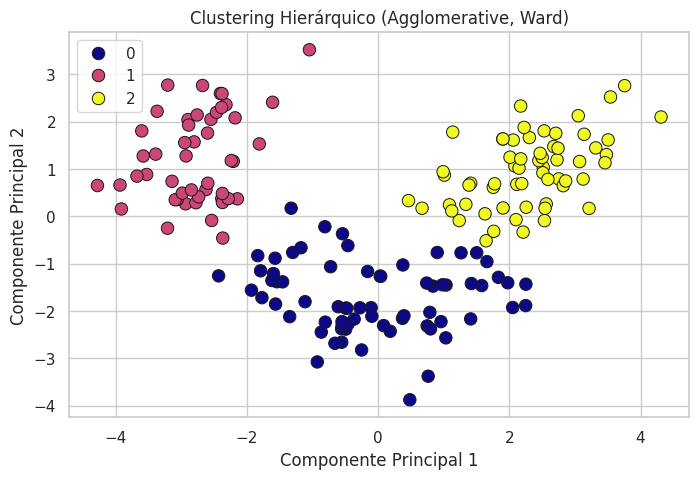

In [4]:
# Instanciando e treinando o Agglomerative Clustering
agg_cluster = AgglomerativeClustering(n_clusters=3, linkage='ward')
agg_labels = agg_cluster.fit_predict(X_pca)

# Avaliação Agglomerative
sil_agg = silhouette_score(X_pca, agg_labels)
print(f"Silhouette Score (Agglomerative): {sil_agg:.4f}")

# Plotagem dos resultados
plt.figure(figsize=(8, 5))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=agg_labels, palette='plasma', s=80, edgecolor='k')
plt.title("Clustering Hierárquico (Agglomerative, Ward)")
plt.xlabel("Componente Principal 1")
plt.ylabel("Componente Principal 2")
plt.legend()
plt.show()

### Validação Cruzada (Estabilidade dos Clusters)
Embora a validação cruzada seja usual em aprendizado supervisionado, podemos aplicá-ela para testar a **estabilidade dos agrupamentos**. Usaremos o `KFold` para dividir o dataset escalonado. Em cada *fold*, o K-Means aprenderá os centroides com os dados de treino, e alocará os dados de teste ao centroide mais próximo. Mediremos o *Silhouette Score* no conjunto de teste para verificar se o modelo generaliza bem a geometria dos clusters.

In [5]:
kf = KFold(n_splits=5, shuffle=True, random_state=42)
test_silhouette_scores = []

for train_idx, test_idx in kf.split(X_pca):
    X_train, X_test = X_pca[train_idx], X_pca[test_idx]

    # Ajusta o modelo apenas com o conjunto de treino
    km_cv = KMeans(n_clusters=3, random_state=42, n_init=10)
    km_cv.fit(X_train)

    # Prediz o cluster para o conjunto de teste (atribui ao centroide mais próximo)
    test_labels = km_cv.predict(X_test)

    # Se um fold tiver menos de 2 clusters preditos, o silhouette score falha,
    # mas com K=3 e dados razoavelmente distribuídos, isso não ocorrerá.
    score = silhouette_score(X_test, test_labels)
    test_silhouette_scores.append(score)

print(f"Silhouette Scores nas partições de Teste (5-Folds):")
for i, sc in enumerate(test_silhouette_scores):
    print(f"Fold {i+1}: {sc:.4f}")

print(f"\nSilhouette Score Médio: {np.mean(test_silhouette_scores):.4f} (+/- {np.std(test_silhouette_scores):.4f})")

Silhouette Scores nas partições de Teste (5-Folds):
Fold 1: 0.6066
Fold 2: 0.5108
Fold 3: 0.5949
Fold 4: 0.5560
Fold 5: 0.5432

Silhouette Score Médio: 0.5623 (+/- 0.0349)


## Discussão sobre os resultados

# **Análise do Pré-processamento e Redução de Dimensionalidade**  
O conjunto de dados contém 178 instâncias e 13 dimensões numéricas. A Análise de Componentes Principais (PCA) retém 55,41% da variância total nas duas primeiras componentes. A dispersão resultante mostra que os dados tendem a se separar em três regiões distintas. Isso valida o uso de algoritmos de clusterização para identificar as cultivares.  

# **Desempenho dos Algoritmos de Agrupamento**
Os métodos K-Means e Agglomerative Clustering produziram resultados consistentes e próximos em termos estatísticos. O K-Means alcançou um Silhouette Score de 0,5611, organizando os pontos em três agrupamentos bem definidos ao redor de seus centroides. O Agglomerative Clustering (critério de Ward) obteve um Silhouette Score de 0,5591, resultando em fronteiras de decisão quase idênticas. Essa convergência é esperada, pois a ligação de Ward e o K-Means otimizam funções semelhantes que minimizam a variância intracluster.  

# **Validação e Estabilidade**
A validação cruzada adaptada (5-Folds) confirmou que as partições são estáveis. Os Silhouette Scores nos conjuntos de teste variaram entre 0,5108 (Fold 2) e 0,6066 (Fold 1). A média de 0,5623 e o baixo desvio padrão de 0,0349 mostram que a estrutura de três agrupamentos reflete uma característica real da distribuição dos dados e tem boa capacidade de generalização.  

# **Possibilidades de Melhoria**

A variância explicada de 55,41% pelo PCA indica que uma parte significativa da informação foi descartada na projeção em duas dimensões. O uso de técnicas não lineares de redução de dimensionalidade, como t-SNE ou UMAP, pode mostrar separações mais claras e preservar melhor a topologia local. Além disso, a aplicação de métodos para otimizar hiperparâmetros, como o método do Cotovelo ou estatística Gap, poderia comprovar matematicamente a escolha de K=3, diminuindo a dependência do conhecimento prévio sobre o número de cultivares originais.